In [135]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

df = pd.read_csv('/content/student_success_raw.csv')

df.head(15)

,Student_ID,Age,Study_Hours_Per_Day,Attendance_Percent,Previous_Score,Assignment_Average,Sleep_Hours,Internet_Quality,Study_Method,Part_Time_Job,Final_Result
0,STU1001,16.0,3.3,76.5,66.3,68.5,4.2,Good,Group Study,Yes,Pass
1,STU1002,22.0,3.8,77.5,54.2,80.6,7.4,NaN,Group Study,No,Pass
2,STU1003,21.0,2.4,58.9,73.5,86.2,9.4,Average,Online Course,No,Pass
3,STU1004,19.0,2.9,74.4,100.0,83.0,9.0,Good,Group Study,No,Pass
4,STU1005,19.0,1.9,67.6,36.6,68.1,9.3,Good,Online Course,Yes,Fail
5,STU1006,23.0,4.0,90.9,70.2,38.8,5.7,good,Tuition,No,Pass
6,STU1007,16.0,1.3,NaN,52.8,63.8,8.1,Good,self study,Yes,Fail
7,STU1008,22.0,3.8,74.0,74.2,79.5,6.1,Good,self study,No,Pass
8,STU1009,17.0,2.6,76.5,65.7,52.4,7.3,Good,self study,No,Fail
9,STU1010,16.0,4.3,81.1,77.2,83.4,5.4,Good,Group Study,Yes,Pass


In [136]:
df.shape

(658, 11)

In [137]:
df.describe()

,Age,Study_Hours_Per_Day,Attendance_Percent,Previous_Score,Assignment_Average,Sleep_Hours
count,641.000000,636.000000,629.000000,632.000000,631.000000,639.000000
mean,20.024961,2.791981,77.169157,63.191930,72.154041,7.056338
std,2.569533,1.465965,14.201448,16.077893,17.888514,1.355583
min,16.000000,-2.000000,-5.000000,-10.000000,-4.000000,-1.000000
25%,18.000000,1.900000,68.000000,52.575000,60.700000,6.200000
50%,20.000000,2.800000,77.900000,64.500000,72.200000,7.100000
75%,22.000000,3.600000,86.900000,73.800000,85.950000,7.900000
max,24.000000,18.000000,145.000000,130.000000,120.000000,19.000000


In [138]:
df.isnull().sum()

,0
Student_ID,0
Age,17
Study_Hours_Per_Day,22
Attendance_Percent,29
Previous_Score,26
Assignment_Average,27
Sleep_Hours,19
Internet_Quality,16
Study_Method,16
Part_Time_Job,14


In [139]:
df.dtypes

,0
Student_ID,object
Age,float64
Study_Hours_Per_Day,float64
Attendance_Percent,float64
Previous_Score,float64
Assignment_Average,float64
Sleep_Hours,float64
Internet_Quality,object
Study_Method,object
Part_Time_Job,object


In [140]:
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

cat_cols = df.select_dtypes(include='object').columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])


In [141]:
df.isnull().sum()

,0
Student_ID,0
Age,0
Study_Hours_Per_Day,0
Attendance_Percent,0
Previous_Score,0
Assignment_Average,0
Sleep_Hours,0
Internet_Quality,0
Study_Method,0
Part_Time_Job,0


In [142]:
df.duplicated().sum()

np.int64(8)

In [143]:
df = df.drop_duplicates()

In [144]:
df.duplicated().sum()

np.int64(0)

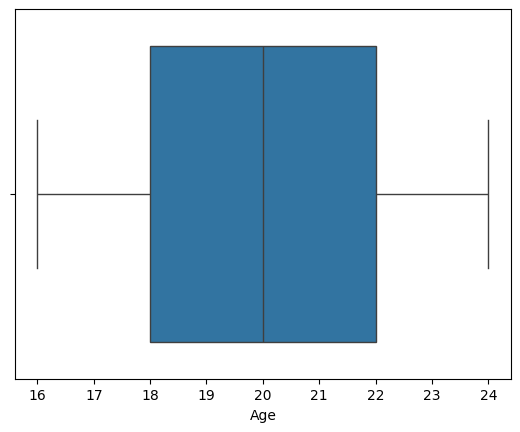

In [145]:
sns.boxplot(x="Age", data=df)
plt.show()

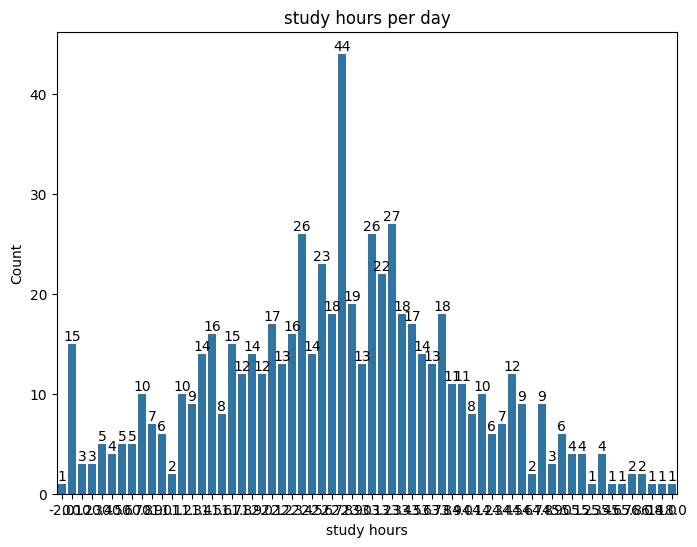

In [146]:
plt.figure(figsize = (8,6))

a = sns.countplot(
    data = df,
    x = "Study_Hours_Per_Day"
)

plt.title("study hours per day")
plt.xlabel("study hours")
plt.ylabel("Count")


for container in a.containers:
  a.bar_label(container)

plt.show()

In [147]:
plt.figure(figsize = (8,6))
a = sns.scatterplot(
    data = df,
    x = "Study_Method"
)

plt.title("Sibsp vs Parch")
plt.xlabel("Sibsp")
plt.ylabel("Parch")
plt.show()

ConversionError: Failed to convert value(s) to axis units: masked_array(data=[--, --, --, --, --, --, --, --, --, --, --, --, --, --,
                   --, --, --, --, --, --, --, --, --, --, --, --, --, --,
                   --, --, --, --, --, --, --, --, --, --, --, --, --, --,
                   --, --, --, --, --, --, --, --, --, --, --, --, --, --,
                   --, --, --, --, --, --, --, --, --, --, --, --, --, --,
                   --, --, --, --, --, --, --, --, --, --, --, --, --, --,
                   --, --, --, --, --, --, --, --, --, --, --, --, --, --,
                   --, --, --, --, --, --, --, --, --, --, --, --, --, --,
                   --, --, --, --, --, --, --, --, --, --, --, --, --, --,
                   --, --, --, --, --, --, --, --, --, --, --, --, --, --,
                   --, --, --, --, --, --, --, --, --, --, --, --, --, --,
                   --, --, --, --, --, --, --, --, --, --, --, --, --, --,
                   --, --, --, --, --, --

<Figure size 800x600 with 1 Axes>

In [148]:
features = [
    "Attendance_Percent",
    "Assignment_Average"
]


In [149]:
x = df[features]
y = df["Final_Result"].map({
    "Fail": 0,
    "Pass": 1
})

In [150]:
x_train,x_test,y_train,y_test = train_test_split(x, y,test_size=0.2,random_state=42)

In [151]:
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((520, 2), (130, 2), (520,), (130,))

In [152]:
def evaluate_model (name, model, x_train, x_test, y_train, y_test):

  model.fit(x_train, y_train)

  predictions = model.predict(x_test)

  mae = mean_absolute_error(y_test, predictions)

  rmse = np.sqrt(

  mean_squared_error(y_test, predictions)
  )
  r2 = r2_score (y_test, predictions)

  print(f"\n{name}")
  print("-" * 40)
  print (f"MAE: {mae:.2f}")
  print (f"RMSE {rmse:.2f}")
  print (f"R2 : {r2:.4f}")

  return model, predictions

In [153]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(
    n_estimators=150,
    max_depth=18,
    random_state=42,
    n_jobs=-1
)
rf, rf_pred = evaluate_model(
    "Random Forest",
    rf,
    x_train,
    x_test,
    y_train,
    y_test
)


Random Forest
----------------------------------------
MAE: 0.43
RMSE 0.52
R2 : -0.0779


In [154]:
from sklearn.tree import DecisionTreeRegressor
tree = DecisionTreeRegressor(
max_depth=10,
random_state=42
)
tree, tree_pred = evaluate_model(
"Decision Tree",
tree,
x_train,
x_test,
y_train,
y_test
)


Decision Tree
----------------------------------------
MAE: 0.42
RMSE 0.60
R2 : -0.4830


In [155]:
from sklearn.tree import LogisticRegression

lr = LogisticRegression(
    n_estimators=150,
    max_depth=18,
    random_state=42,
    n_jobs=-1
)
lr, lr_pred = evaluate_model(
    "Logistic regressiom",
    rf,
    x_train,
    x_test,
    y_train,
    y_test
)


Logistic regression
----------------------------------------
MAE: 0.41
RMSE 0.64
R2 : -0.6559


In [156]:
df["Internet_Quality"] = df["Internet_Quality"].str.strip().replace({
    "good": "Good",
    "average": "Average",
    "poor": "Poor"
})

In [157]:
df["Study_Method"] = df["Study_Method"].str.strip().replace({
    "self study": "Self study"
})

In [158]:
df["Part_Time_Job"] = df["Part_Time_Job"].str.strip().replace({
    "yes": "Yes",
    "no": "No"
})

In [159]:
df.head(15)

,Student_ID,Age,Study_Hours_Per_Day,Attendance_Percent,Previous_Score,Assignment_Average,Sleep_Hours,Internet_Quality,Study_Method,Part_Time_Job,Final_Result
0,STU1001,16.0,3.3,76.5,66.3,68.5,4.2,Good,Group Study,Yes,Pass
1,STU1002,22.0,3.8,77.5,54.2,80.6,7.4,Good,Group Study,No,Pass
2,STU1003,21.0,2.4,58.9,73.5,86.2,9.4,Average,Online Course,No,Pass
3,STU1004,19.0,2.9,74.4,100.0,83.0,9.0,Good,Group Study,No,Pass
4,STU1005,19.0,1.9,67.6,36.6,68.1,9.3,Good,Online Course,Yes,Fail
5,STU1006,23.0,4.0,90.9,70.2,38.8,5.7,Good,Tuition,No,Pass
6,STU1007,16.0,1.3,77.9,52.8,63.8,8.1,Good,Self study,Yes,Fail
7,STU1008,22.0,3.8,74.0,74.2,79.5,6.1,Good,Self study,No,Pass
8,STU1009,17.0,2.6,76.5,65.7,52.4,7.3,Good,Self study,No,Fail
9,STU1010,16.0,4.3,81.1,77.2,83.4,5.4,Good,Group Study,Yes,Pass


In [160]:
import joblib
joblib.dump(lr, 'logistic_regression_model.pkl')
joblib.dump(tree, 'decision_tree_model.pkl')
joblib.dump(rf, 'random_forest_model.pkl')

['random_forest_model.pkl']

In [172]:
#@title Student Information Form
Age = 15 #@param {type:"number"}
Study_Hours_Per_Day = 3.5 #@param {type:"number"}
Attendance_Percent = 85.0 #@param {type: "number"}
Previous_Score = 75.0 #@param {type: "number"}
Assignment_Average = 80.0 #@param {type:"number"}
Sleep_Hours = 7.0 #@param {type:"number"}
Internet_Quality = "Good" #@param ["Good", "Average", "Poor"]
Study_Method = "Group Study" #@param ["Group Study", "Online Course", "Self-study"]
Part_Time_Job = "No" #@param ["Yes", "No"]


import pandas as pd
import numpy as np

input_data = pd.DataFrame([{
    'Age': Age,
    'Study_Hours_Per_Day': Study_Hours_Per_Day,
    'Attendance_Percent': Attendance_Percent,
    'Previous_Score': Previous_Score,
    'Assignment_Average': Assignment_Average,
    'Sleep_Hours': Sleep_Hours,
    'Internet_Quality': Internet_Quality,
    'Study_Method': Study_Method,
    'Part_Time_Job': Part_Time_Job
}])

# One-hot encode the input
input_encoded = pd.get_dummies(input_data)

# Align columns with model training features (X)
for col in x.columns:
    if col not in input_encoded.columns:
        input_encoded[col] = 0

# Reorder columns to match training set exactly
input_encoded = input_encoded[x.columns]

# Predictions (use 'lr_pred' with lowercase 'L', not digit '1')
lr_pred = lr.predict(input_encoded)[0]
rf_pred = rf.predict(input_encoded)[0]
tree_pred = tree.predict(input_encoded)[0]

rf_label = int(round(rf_pred))
tree_label = int(round(tree_pred))

map_result = {1: 'Pass', 0: 'Fail'}

print(f"Logistic Regression Prediction: {map_result[lr_pred]}")
print(f"Random Forest Prediction: {map_result[rf_pred]}")
print(f"Decision tree prediction: {map_result[tree_pred]}")

Logistic Regression Prediction: Pass
Random Forest Prediction: Fail
Decision tree prediction: Fail
